# Sampling Distributions and Confidence Intervals

Lesson 11 showed that sample means are approximately normal. But real analyses face a problem: we almost never know the population standard deviation $\sigma$. Replacing it with the sample estimate $s$ changes the distribution of our test statistics — and gives rise to the three distributions behind nearly every classical test: **Student's t**, **chi-square ($\chi^2$)** and **F**.

In this lesson you will learn where these distributions come from, how to use them to build **confidence intervals**, and how confidence intervals and hypothesis tests are two views of the same idea.

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. Student's t Distribution

If $X_1, \dots, X_n$ are i.i.d. $N(\mu, \sigma^2)$, then

$$
Z = \frac{\bar{X} - \mu}{\sigma / \sqrt{n}} \sim N(0, 1)
\qquad\text{but}\qquad
T = \frac{\bar{X} - \mu}{s / \sqrt{n}} \sim t_{\,n-1}
$$

Because $s$ is itself random (sometimes too small, sometimes too large), $T$ varies more than $Z$: the t distribution has **heavier tails**. The parameter **degrees of freedom** $df = n - 1$ controls how heavy; as $df \to \infty$, $t_{df} \to N(0, 1)$.

*History: William Gosset derived it in 1908 while working for the Guinness brewery on small samples of barley, and published under the pen name "Student".*

  df t_0.975 P_abs_T_gt_1.96
   2   4.303          0.1891
   5   2.571          0.1073
  10   2.228          0.0784
  20   2.086          0.0641
  30   2.042          0.0593
 100   1.984          0.0528
 Inf   1.960          0.0500


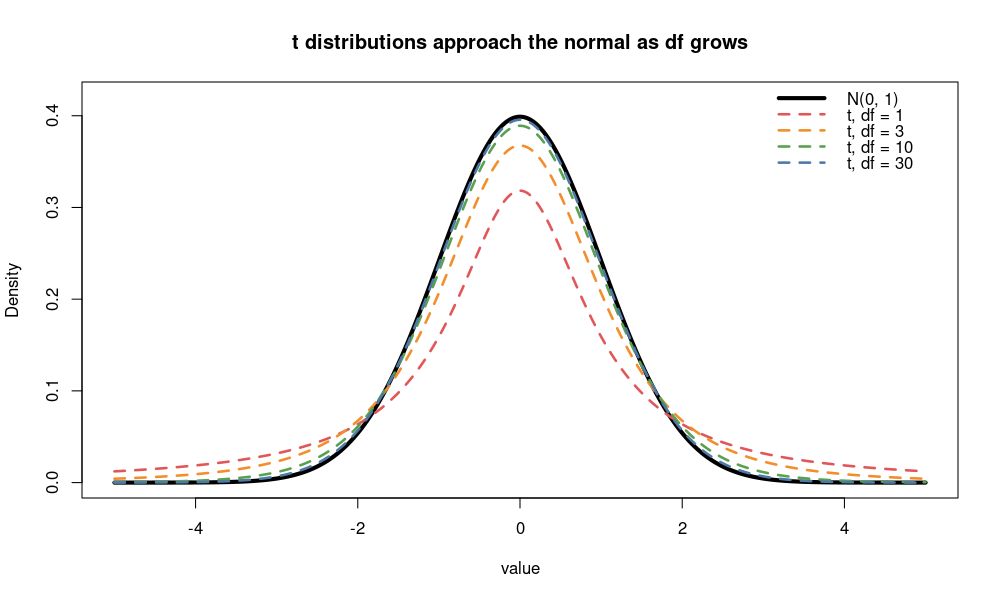

In [2]:
xs <- seq(-5, 5, length.out = 500)
dfs <- c(1, 3, 10, 30)
cols <- c("#E15759", "#F28E2B", "#59A14F", "#4E79A7")

plot(xs, dnorm(xs), type = "l", lwd = 4, col = "black", ylim = c(0, 0.42),
     main = "t distributions approach the normal as df grows", xlab = "value", ylab = "Density")
for (i in seq_along(dfs)) lines(xs, dt(xs, dfs[i]), lwd = 2.5, col = cols[i], lty = 2)
legend("topright", c("N(0, 1)", paste("t, df =", dfs)), col = c("black", cols), lwd = c(4, rep(2.5, 4)),
       lty = c(1, rep(2, 4)), bty = "n")

crit <- data.frame(df = c(2, 5, 10, 20, 30, 100, Inf))
crit$t_0.975 <- round(qt(0.975, crit$df), 3)
crit$P_abs_T_gt_1.96 <- round(2 * (1 - pt(1.96, crit$df)), 4)
print(crit, row.names = FALSE)

The table shows the problem concretely: with only 5 degrees of freedom, a value beyond $\pm1.96$ happens about 11% of the time, not 5%. Using the normal critical value 1.96 with small samples makes intervals too narrow and tests too eager to reject.

  n coverage_with_z coverage_with_t
  3           0.808           0.947
  5           0.878           0.952
 10           0.919           0.950
 20           0.930           0.953
 50           0.945           0.950


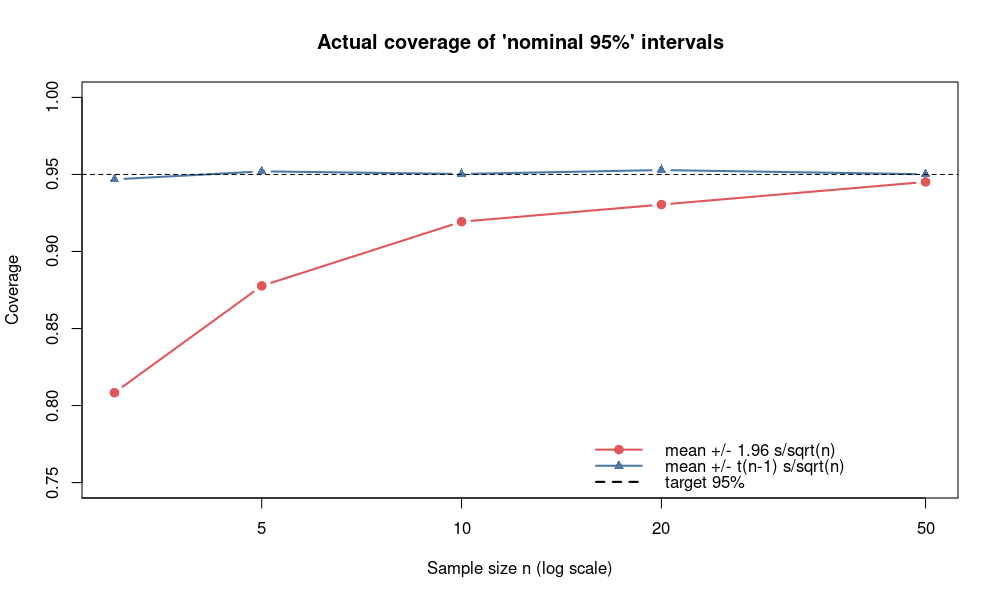

In [3]:
# Simulation: build 95% intervals for the mean with z = 1.96 vs t critical values, using s
set.seed(12)
coverage <- function(n, crit_fun, reps = 20000) {
  mean(replicate(reps, {
    x <- rnorm(n, mean = 10, sd = 3)
    half <- crit_fun(n) * sd(x) / sqrt(n)
    abs(mean(x) - 10) <= half
  }))
}
ns <- c(3, 5, 10, 20, 50)
cov_z <- sapply(ns, coverage, crit_fun = function(n) 1.96)
cov_t <- sapply(ns, coverage, crit_fun = function(n) qt(0.975, n - 1))
print(data.frame(n = ns, coverage_with_z = round(cov_z, 3), coverage_with_t = round(cov_t, 3)), row.names = FALSE)

plot(ns, cov_z, type = "b", pch = 19, lwd = 2, col = "#E15759", ylim = c(0.75, 1), log = "x",
     main = "Actual coverage of 'nominal 95%' intervals", xlab = "Sample size n (log scale)", ylab = "Coverage")
lines(ns, cov_t, type = "b", pch = 17, lwd = 2, col = "#4E79A7")
abline(h = 0.95, lty = 2)
legend("bottomright", c("mean +/- 1.96 s/sqrt(n)", "mean +/- t(n-1) s/sqrt(n)", "target 95%"),
       col = c("#E15759", "#4E79A7", "black"), pch = c(19, 17, NA), lty = c(1, 1, 2), lwd = 2, bty = "n")

*Insight: The t interval hits 95% coverage at every sample size, while the z interval with $s$ falls short for small $n$ (about 80% at $n = 3$). This is why `t.test()`, not a z formula, is the default for means.*

## 2. The Chi-square Distribution

If $Z_1, \dots, Z_k$ are independent standard normals, then

$$
Q = Z_1^2 + Z_2^2 + \dots + Z_k^2 \sim \chi^2_k
$$

It is always positive, right-skewed, with mean $k$ and variance $2k$. Two key uses:

- **Variance of a normal sample**: $\dfrac{(n-1)s^2}{\sigma^2} \sim \chi^2_{n-1}$ → confidence intervals and tests for $\sigma^2$.
- **Counts in categories**: $\sum \frac{(O - E)^2}{E}$ is approximately $\chi^2$ → goodness-of-fit and independence tests (Lesson 19).

Simulated mean: 6.99 (theory: df = 7) | variance: 14.101 (theory: 14)


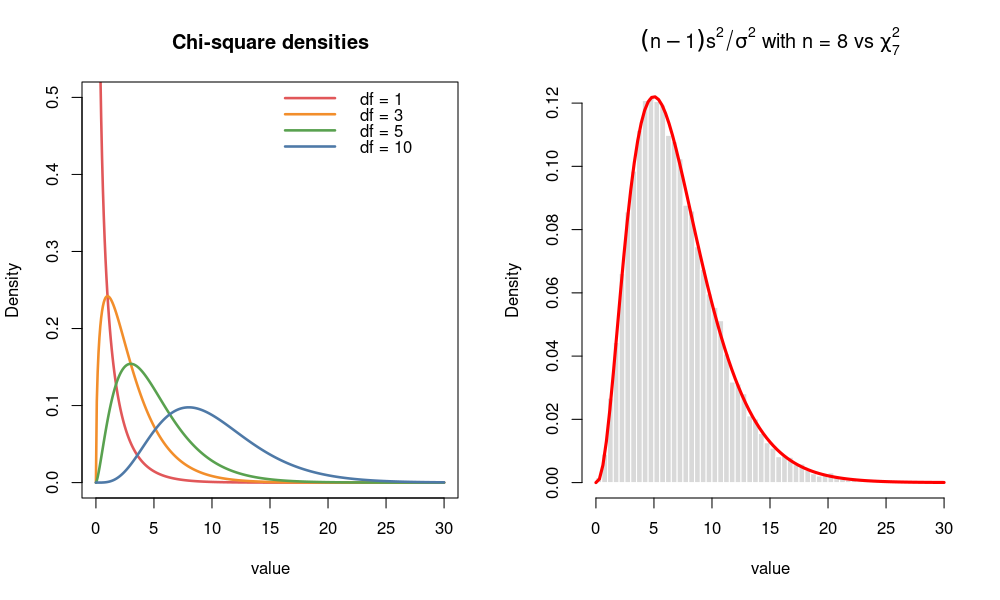

In [4]:
set.seed(22)
n <- 8; sigma <- 3
stat <- replicate(20000, (n - 1) * var(rnorm(n, 0, sigma)) / sigma^2)

par(mfrow = c(1, 2))
xs <- seq(0, 30, length.out = 400)
plot(xs, dchisq(xs, 1), type = "l", lwd = 2.5, col = "#E15759", ylim = c(0, 0.5),
     main = "Chi-square densities", xlab = "value", ylab = "Density")
for (k in c(3, 5, 10)) lines(xs, dchisq(xs, k), lwd = 2.5, col = c("#F28E2B", "#59A14F", "#4E79A7")[match(k, c(3, 5, 10))])
legend("topright", paste("df =", c(1, 3, 5, 10)), col = c("#E15759", "#F28E2B", "#59A14F", "#4E79A7"), lwd = 2.5, bty = "n")

hist(stat, breaks = 60, freq = FALSE, col = "grey85", border = "white", xlim = c(0, 30),
     main = expression((n - 1) * s^2 / sigma^2 ~ "with n = 8 vs" ~ chi[7]^2), xlab = "value")
curve(dchisq(x, n - 1), add = TRUE, lwd = 3, col = "red")
cat("Simulated mean:", round(mean(stat), 3), "(theory: df = 7) | variance:", round(var(stat), 3), "(theory: 14)\n")

## 3. The F Distribution

The ratio of two independent chi-square variables, each divided by its degrees of freedom, follows an **F distribution**:

$$
F = \frac{\chi^2_{d_1} / d_1}{\chi^2_{d_2} / d_2} \sim F_{d_1, d_2}
\qquad\Rightarrow\qquad
\frac{s_1^2 / \sigma_1^2}{s_2^2 / \sigma_2^2} \sim F_{n_1 - 1,\, n_2 - 1}
$$

It is the distribution of a **ratio of variances**: the basis of the variance-ratio test (`var.test()`), ANOVA (between-group vs within-group variance, Lessons 13 and 17) and the overall F-test in regression.


	F test to compare two variances

data:  machine_A and machine_B
F = 0.4192, num df = 14, denom df = 14, p-value = 0.1155
alternative hypothesis: true ratio of variances is not equal to 1
95 percent confidence interval:
 0.1407389 1.2486331
sample estimates:
ratio of variances 
         0.4192031 


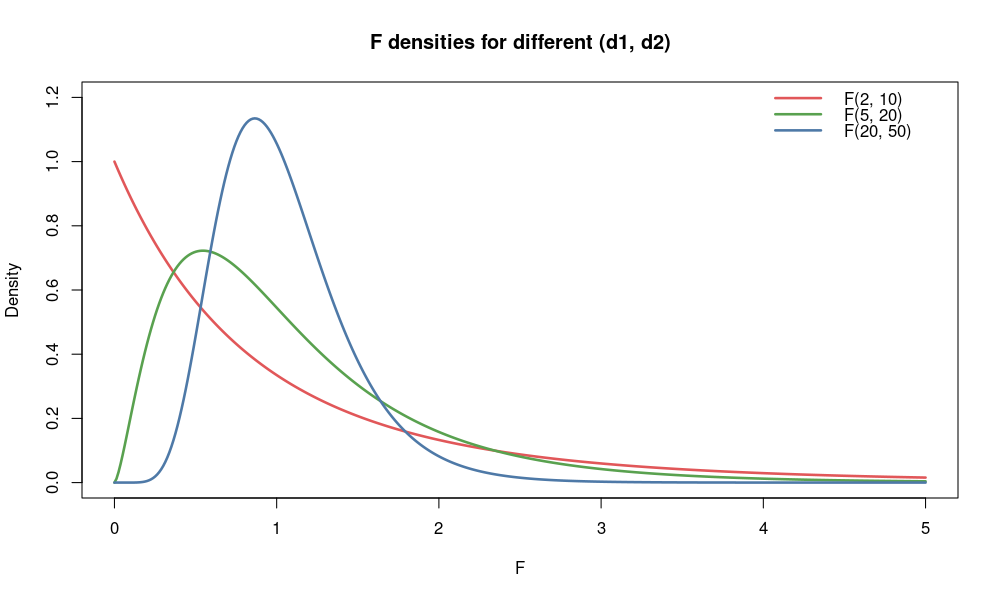

In [5]:
xs <- seq(0, 5, length.out = 400)
plot(xs, df(xs, 2, 10), type = "l", lwd = 2.5, col = "#E15759", ylim = c(0, 1.2),
     main = "F densities for different (d1, d2)", xlab = "F", ylab = "Density")
lines(xs, df(xs, 5, 20), lwd = 2.5, col = "#59A14F")
lines(xs, df(xs, 20, 50), lwd = 2.5, col = "#4E79A7")
legend("topright", c("F(2, 10)", "F(5, 20)", "F(20, 50)"), col = c("#E15759", "#59A14F", "#4E79A7"), lwd = 2.5, bty = "n")

set.seed(33)
machine_A <- rnorm(15, 50, 2)
machine_B <- rnorm(15, 50, 3.5)
var.test(machine_A, machine_B)

## 4. Confidence Intervals: the General Recipe

Almost every confidence interval has the same shape:

$$
\text{estimate} \;\pm\; \text{critical value} \times \text{standard error}
$$

| Parameter | Estimate | Standard error | Critical value | R |
|---|---|---|---|---|
| mean $\mu$ | $\bar{x}$ | $s/\sqrt{n}$ | $t_{\alpha/2,\,n-1}$ | `t.test(x)` |
| difference $\mu_1 - \mu_2$ | $\bar{x}_1 - \bar{x}_2$ | $\sqrt{s_1^2/n_1 + s_2^2/n_2}$ | $t$ (Welch df) | `t.test(x, y)` |
| proportion $p$ | $\hat{p}$ | $\sqrt{\hat{p}(1-\hat{p})/n}$ | $z_{\alpha/2}$ | `prop.test(k, n)` (Wilson) |
| variance $\sigma^2$ | $s^2$ | — (not symmetric) | $\chi^2$ quantiles | formula below |

For the variance the interval is not symmetric: $\left[\dfrac{(n-1)s^2}{\chi^2_{1-\alpha/2}},\; \dfrac{(n-1)s^2}{\chi^2_{\alpha/2}}\right]$.

In [6]:
set.seed(44)
coffee_ml <- rnorm(25, mean = 248, sd = 6)     # a machine that should pour 250 ml
n <- length(coffee_ml); xbar <- mean(coffee_ml); s <- sd(coffee_ml)

# Mean: manual vs t.test
half <- qt(0.975, n - 1) * s / sqrt(n)
cat(sprintf("Mean      : %.2f ml, 95%% CI manual [%.2f, %.2f] | t.test [%.2f, %.2f]\n",
            xbar, xbar - half, xbar + half, t.test(coffee_ml)$conf.int[1], t.test(coffee_ml)$conf.int[2]))

# Variance and SD via chi-square
ci_var <- (n - 1) * s^2 / qchisq(c(0.975, 0.025), n - 1)
cat(sprintf("SD        : %.2f ml, 95%% CI [%.2f, %.2f]\n", s, sqrt(ci_var[1]), sqrt(ci_var[2])))

# Proportion: 37 of 120 customers bought a dessert
k <- 37; m <- 120; p_hat <- k / m
wald   <- p_hat + c(-1, 1) * 1.96 * sqrt(p_hat * (1 - p_hat) / m)
wilson <- prop.test(k, m, correct = FALSE)$conf.int
cat(sprintf("Proportion: %.3f, Wald [%.3f, %.3f] | Wilson [%.3f, %.3f]\n", p_hat, wald[1], wald[2], wilson[1], wilson[2]))

# Difference in means (Welch)
set.seed(45)
old_recipe <- rnorm(30, 7.1, 1.2); new_recipe <- rnorm(30, 7.8, 1.0)
ci_diff <- t.test(new_recipe, old_recipe)$conf.int
cat(sprintf("Difference: new - old rating = %.2f, 95%% CI [%.2f, %.2f]\n",
            mean(new_recipe) - mean(old_recipe), ci_diff[1], ci_diff[2]))

Mean      : 247.08 ml, 95% CI manual [244.37, 249.79] | t.test [244.37, 249.79]


SD        : 6.57 ml, 95% CI [5.13, 9.14]


Proportion: 0.308, Wald [0.226, 0.391] | Wilson [0.233, 0.396]


Difference: new - old rating = 0.91, 95% CI [0.30, 1.51]


## 5. Why the Simple (Wald) Interval for a Proportion Fails

The textbook interval $\hat{p} \pm 1.96\sqrt{\hat{p}(1-\hat{p})/n}$ ("Wald") behaves badly for small $n$ or $p$ near 0 or 1: it can even extend below 0. The **Wilson** interval (used by `prop.test`) fixes this. The simulation below measures the real coverage of each method for $n = 30$.

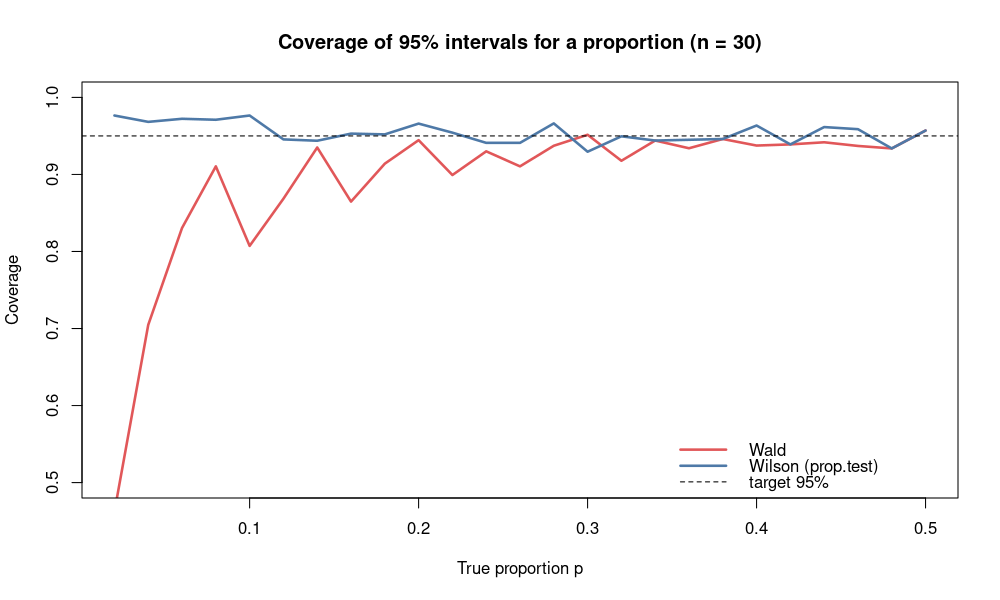

In [7]:
coverage_prop <- function(p, n = 30, reps = 4000) {
  k <- rbinom(reps, n, p); ph <- k / n
  wald_lo <- ph - 1.96 * sqrt(ph * (1 - ph) / n); wald_hi <- ph + 1.96 * sqrt(ph * (1 - ph) / n)
  z <- 1.96; centre <- (ph + z^2 / (2 * n)) / (1 + z^2 / n)
  hw <- z * sqrt(ph * (1 - ph) / n + z^2 / (4 * n^2)) / (1 + z^2 / n)
  c(wald = mean(wald_lo <= p & p <= wald_hi), wilson = mean(centre - hw <= p & p <= centre + hw))
}
set.seed(55)
ps <- seq(0.02, 0.5, by = 0.02)
cov <- t(sapply(ps, coverage_prop))

plot(ps, cov[, "wald"], type = "l", lwd = 2.5, col = "#E15759", ylim = c(0.5, 1),
     main = "Coverage of 95% intervals for a proportion (n = 30)", xlab = "True proportion p", ylab = "Coverage")
lines(ps, cov[, "wilson"], lwd = 2.5, col = "#4E79A7")
abline(h = 0.95, lty = 2)
legend("bottomright", c("Wald", "Wilson (prop.test)", "target 95%"), col = c("#E15759", "#4E79A7", "black"),
       lwd = c(2.5, 2.5, 1), lty = c(1, 1, 2), bty = "n")

## 6. Confidence Intervals and Hypothesis Tests Are Two Sides of One Coin

A two-sided test at level $\alpha$ rejects $H_0: \mu = \mu_0$ **exactly when** the $(1-\alpha)$ confidence interval does not contain $\mu_0$. A confidence interval is therefore the set of all null values you would *not* reject — and it also shows the size and precision of the effect, which a p-value alone hides.

 mu0 p_value inside_CI rejected
 244 0.02760     FALSE     TRUE
 245 0.12600      TRUE    FALSE
 246 0.41900      TRUE    FALSE
 247 0.95100      TRUE    FALSE
 248 0.49100      TRUE    FALSE
 249 0.15700      TRUE    FALSE
 250 0.03610     FALSE     TRUE
 251 0.00648     FALSE     TRUE
 252 0.00101     FALSE     TRUE


Every rejected mu0 lies outside the CI and vice versa: TRUE 


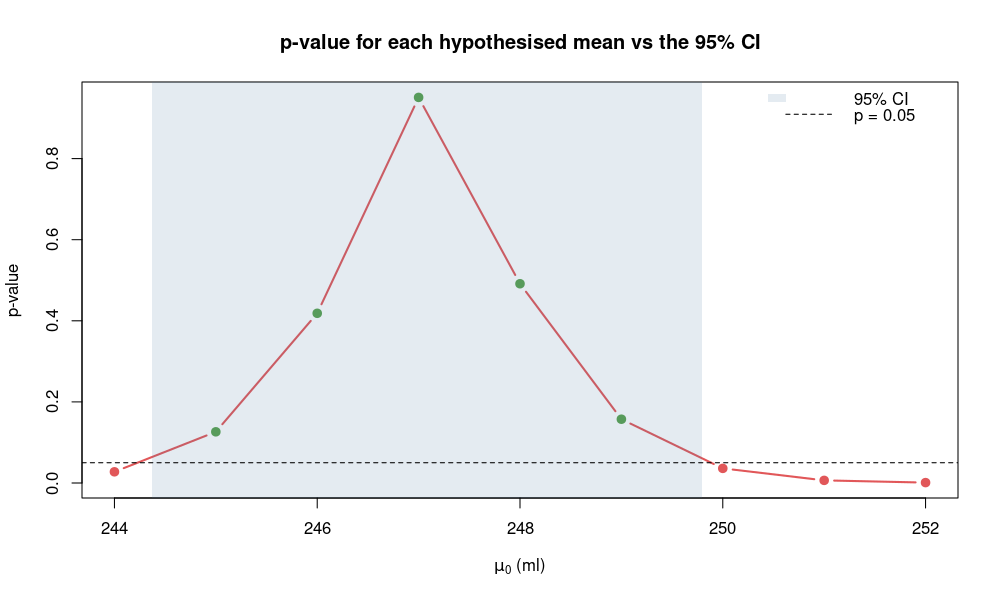

In [8]:
candidates <- seq(244, 252, by = 1)
dual <- data.frame(mu0 = candidates,
                   p_value = sapply(candidates, function(m) t.test(coffee_ml, mu = m)$p.value))
ci <- t.test(coffee_ml)$conf.int
dual$inside_CI <- dual$mu0 >= ci[1] & dual$mu0 <= ci[2]
dual$rejected  <- dual$p_value < 0.05
print(transform(dual, p_value = signif(p_value, 3)), row.names = FALSE)
cat("Every rejected mu0 lies outside the CI and vice versa:", all(dual$rejected == !dual$inside_CI), "\n")

plot(dual$mu0, dual$p_value, type = "b", pch = 19, lwd = 2, col = ifelse(dual$rejected, "#E15759", "#59A14F"),
     main = "p-value for each hypothesised mean vs the 95% CI", xlab = expression(mu[0] ~ "(ml)"), ylab = "p-value")
rect(ci[1], -1, ci[2], 2, col = adjustcolor("#4E79A7", 0.15), border = NA)
abline(h = 0.05, lty = 2)
legend("topright", c("95% CI", "p = 0.05"), fill = c(adjustcolor("#4E79A7", 0.15), NA), border = NA,
       lty = c(NA, 2), bty = "n")

## 7. Interpreting a Confidence Interval Correctly

- **Correct**: "If we repeated the study many times, 95% of the intervals built this way would contain the true mean." (Lesson 11 showed this with 100 intervals.)
- **Incorrect**: "There is a 95% probability that the true mean lies in *this* interval." Once computed, a particular interval either contains $\mu$ or it does not. (A Bayesian *credible* interval does support that statement.)
- A wider interval means **less precision**; to halve the width you need about four times as many observations.

*Insight: Report confidence intervals by default. "The new recipe raised ratings by 0.9 points (95% CI 0.3 to 1.5)" tells a decision-maker far more than "p = 0.01".*

## Real-World Use Case or Analogy

A confidence interval is like a **fishing net**. The true value is a fish you can't see. The *method* of throwing the net catches the fish 95% of the time, but for any single throw you don't know whether you caught it. A bigger sample gives a smaller, more precise net that still catches the fish 95% of the time.

- **t distribution**: the "extra caution" you need when you estimate the spread from the same small sample you are testing — like a weather forecaster who widens the forecast range when they have only a few days of data.
- **Chi-square**: quality control for consistency — a coffee machine can pour the right *average* amount yet be far too *variable*.
- **F distribution**: comparing the consistency of two machines, or the variability between groups vs within groups in ANOVA.